Deep Learning / NLP Text Classifier with PyTorch
Sentiment Analysis: Positive vs. Negative Movie Reviews

**Objective:** Build and evaluate a neural-network text classifier using TF-IDF features and PyTorch.

**Pipeline:** text cleaning → TF-IDF vectorization → train/validation/test split → multilayer neural network → early stopping → learning curves → unseen-text predictions.

> This notebook includes a small, self-contained demonstration dataset so it can run without downloading a dataset. For a production-quality result, replace or expand the sample texts with a larger labeled dataset.

1. Setup and imports

Run this cell first. If a package is missing in your environment, uncomment the installation line.

In [1]:

import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


2. Prepare the dataset

The target labels are `1 = positive` and `0 = negative`. The examples are short illustrative review snippets.

In [2]:
texts = ['Absolutely loved this movie, the acting was brilliant and the story was moving.', 'A wonderful film with a clever script and excellent performances.', 'Fantastic from beginning to end, entertaining and beautifully made.', 'The cast was superb and the direction was thoughtful.', 'I enjoyed every minute, a delightful and memorable experience.', 'An inspiring story with great characters and emotional depth.', 'Funny, charming, and surprisingly heartwarming.', 'The cinematography was gorgeous and the soundtrack was excellent.', 'A brilliant film that kept me engaged throughout.', 'One of the best films I have watched this year.', 'Strong performances make this a highly enjoyable movie.', 'Beautiful storytelling, excellent pacing, and a satisfying ending.', 'This movie was entertaining, clever, and full of heart.', 'A moving masterpiece with unforgettable scenes.', 'Smart writing and wonderful acting made this film special.', 'I would happily watch this fantastic movie again.', 'The plot was engaging and the characters felt authentic.', 'An impressive achievement, both visually and emotionally.', 'Great dialogue, excellent direction, and a powerful story.', 'This was a delightful surprise and I highly recommend it.', 'The film was uplifting and genuinely funny.', 'Every scene was compelling and the ending was perfect.', 'An outstanding performance from the entire cast.', 'Creative, original, and thoroughly enjoyable storytelling.', 'Warm, witty, and beautifully acted movie.', 'An excellent film with a touching message.', 'The pacing was perfect and the story was captivating.', 'Impressive visuals and a genuinely entertaining plot.', 'A fresh and exciting movie that exceeded expectations.', 'Wonderful characters and a truly satisfying experience.', 'I hated this movie, the acting was poor and the story was boring.', 'A terrible film with a weak script and disappointing performances.', 'Awful from beginning to end, dull and badly made.', 'The cast was unconvincing and the direction was messy.', 'I regret watching it, a tedious and forgettable experience.', 'A confusing story with flat characters and no emotional depth.', 'Not funny, not charming, and painfully predictable.', 'The cinematography was dull and the soundtrack was annoying.', 'A disappointing film that failed to keep me engaged.', 'One of the worst films I have watched this year.', 'Weak performances make this an unpleasant movie.', 'Poor storytelling, terrible pacing, and an unsatisfying ending.', 'This movie was boring, predictable, and poorly written.', 'A forgettable mess with scenes that made no sense.', 'Lazy writing and wooden acting ruined this film.', 'I would never watch this terrible movie again.', 'The plot was confusing and the characters felt fake.', 'A frustrating failure, both visually and emotionally.', 'Bad dialogue, weak direction, and an unbelievable story.', 'This was a huge disappointment and I cannot recommend it.', 'The film was depressing and not funny at all.', 'Every scene dragged and the ending was awful.', 'An embarrassing performance from the entire cast.', 'Unoriginal, dull, and thoroughly unpleasant storytelling.', 'Cold, tedious, and badly acted movie.', 'A poor film with no meaningful message.', 'The pacing was terrible and the story was tedious.', 'Cheap visuals and a completely uninteresting plot.', 'A stale and frustrating movie that missed expectations.', 'Unlikable characters and a deeply unsatisfying experience.']
labels = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

data = pd.DataFrame({"text": texts, "label": labels})
data["sentiment"] = data["label"].map({1: "Positive", 0: "Negative"})
print("Dataset shape:", data.shape)
display(data.sample(6, random_state=SEED))
print("\\nClass distribution:")
print(data["sentiment"].value_counts())

Dataset shape: (60, 3)


,text,label,sentiment
0,"Absolutely loved this movie, the acting was br...",1,Positive
5,An inspiring story with great characters and e...,1,Positive
36,"Not funny, not charming, and painfully predict...",0,Negative
45,I would never watch this terrible movie again.,0,Negative
13,A moving masterpiece with unforgettable scenes.,1,Positive
54,"Cold, tedious, and badly acted movie.",0,Negative


\nClass distribution:
sentiment
Positive    30
Negative    30
Name: count, dtype: int64


3. Split data and convert text to TF-IDF vectors

The test set is held out until final evaluation. The vectorizer is fitted only on the training text to avoid data leakage.

In [3]:
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    data["text"], data["label"], test_size=0.30,
    random_state=SEED, stratify=data["label"]
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50,
    random_state=SEED, stratify=y_temp
)

vectorizer = TfidfVectorizer(
    lowercase=True, stop_words="english",
    ngram_range=(1, 2), max_features=3000
)
X_train = vectorizer.fit_transform(X_train_text).toarray().astype(np.float32)
X_val = vectorizer.transform(X_val_text).toarray().astype(np.float32)
X_test = vectorizer.transform(X_test_text).toarray().astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Train: (42, 270) Validation: (9, 270) Test: (9, 270)
Vocabulary size: 270


4. Build the neural network

The model uses two fully connected hidden layers, ReLU activations, Batch Normalization, and Dropout. A single sigmoid output gives the positive-class probability.

In [4]:
class SentimentClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.35),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

model = SentimentClassifier(X_train.shape[1]).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

print(model)

SentimentClassifier(
  (network): Sequential(
    (0): Linear(in_features=270, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


5. Train with validation and early stopping

Training stops when validation loss does not improve for several epochs. The best model weights are restored.

In [5]:
def make_loader(X, y, batch_size=8, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, y_train_np, shuffle=True)
val_loader = make_loader(X_val, y_val_np)

def evaluate_loss(model, loader):
    model.eval()
    total_loss, total = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * len(yb)
            total += len(yb)
    return total_loss / total

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
patience, patience_counter = 15, 0
max_epochs = 150

for epoch in range(max_epochs):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(yb)
        predictions = (torch.sigmoid(logits) >= 0.5).float()
        correct += (predictions == yb).sum().item()
        total += len(yb)

    train_loss = total_loss / total
    train_acc = correct / total
    val_loss = evaluate_loss(model, val_loader)

    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            probs = torch.sigmoid(model(xb))
            val_correct += ((probs >= 0.5).float() == yb).sum().item()
            val_total += len(yb)
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:03d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")

    if patience_counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

if best_state is not None:
    model.load_state_dict(best_state)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 010 | train loss 0.3636 | val loss 0.6145 | val acc 0.778
Epoch 020 | train loss 0.1456 | val loss 0.5172 | val acc 0.778
Epoch 030 | train loss 0.0756 | val loss 0.5117 | val acc 0.778
Early stopping at epoch 39
Best validation loss: 0.4886


6. Plot loss and accuracy convergence curves

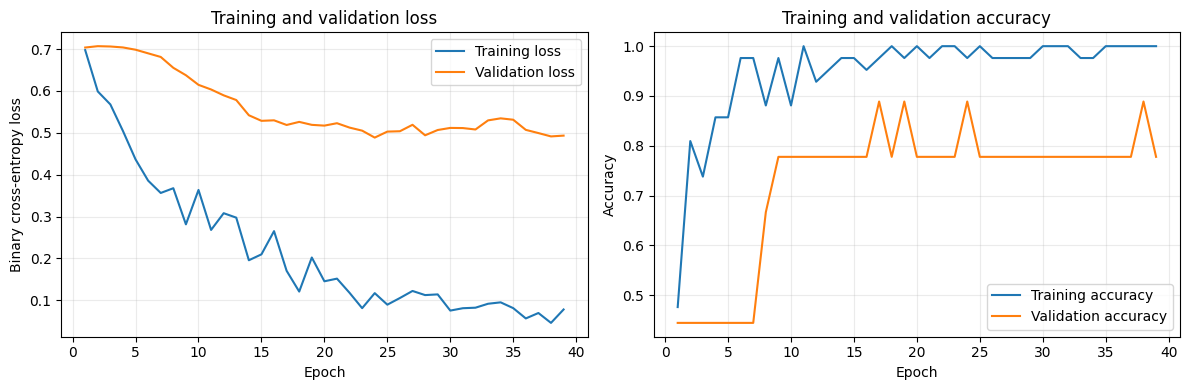

In [6]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(alpha=0.25)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="Training accuracy")
plt.plot(epochs, history["val_acc"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

7. Evaluate on the unseen test set

The test set was not used for fitting the vectorizer or training the model.

Test accuracy: 0.333
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.33      0.20      0.25         5
    Positive       0.33      0.50      0.40         4

    accuracy                           0.33         9
   macro avg       0.33      0.35      0.33         9
weighted avg       0.33      0.33      0.32         9



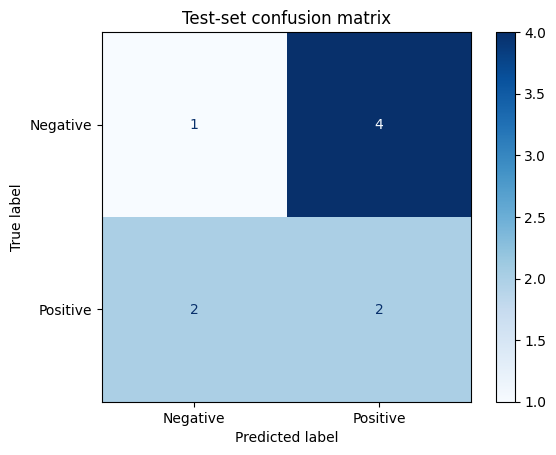

In [7]:
model.eval()
with torch.no_grad():
    test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
    test_probabilities = torch.sigmoid(model(test_tensor)).cpu().numpy()
    test_predictions = (test_probabilities >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test_np, test_predictions)
print(f"Test accuracy: {test_accuracy:.3f}")
print("\\nClassification report:")
print(classification_report(
    y_test_np, test_predictions,
    labels=[0, 1], target_names=["Negative", "Positive"],
    zero_division=0
))

cm = confusion_matrix(y_test_np, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Negative", "Positive"]
).plot(cmap="Blues")
plt.title("Test-set confusion matrix")
plt.show()

8. Predict sentiment for new, unseen text

The confidence shown is the model's estimated probability for the predicted class. It is not a guarantee that the prediction is correct.

In [8]:
def predict_sentiment(sample_texts):
    features = vectorizer.transform(sample_texts).toarray().astype(np.float32)
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(features, dtype=torch.float32).to(device))
        positive_probs = torch.sigmoid(logits).cpu().numpy()

    results = []
    for text, p_pos in zip(sample_texts, positive_probs):
        label = "Positive" if p_pos >= 0.5 else "Negative"
        confidence = p_pos if label == "Positive" else 1 - p_pos
        results.append({
            "Text": text,
            "Predicted sentiment": label,
            "Confidence": f"{confidence:.1%}"
        })
    return pd.DataFrame(results)

new_samples = [
    "The performances were wonderful and I loved the story.",
    "The movie was dull, confusing, and poorly acted.",
    "A charming film with a satisfying ending.",
    "I found the plot boring and the dialogue terrible."
]
display(predict_sentiment(new_samples))

,Text,Predicted sentiment,Confidence
0,The performances were wonderful and I loved th...,Positive,74.0%
1,"The movie was dull, confusing, and poorly acted.",Negative,83.1%
2,A charming film with a satisfying ending.,Positive,83.0%
3,I found the plot boring and the dialogue terri...,Negative,84.9%


9. Conclusion

This project demonstrates an end-to-end binary NLP classification pipeline using TF-IDF and a PyTorch multilayer neural network. The model was trained with Batch Normalization, Dropout, Adam optimization, and validation-based early stopping. Training/validation curves and held-out test metrics were generated, and the final function predicts sentiment with a confidence estimate.

**Limitations:** The included dataset is deliberately small and illustrative. Its test score should not be treated as evidence of real-world performance. For a stronger submission, use a larger balanced dataset (for example, a labeled movie-review dataset), rerun the notebook, and discuss generalization, class balance, and possible overfitting.